In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Configure matplotlib to output both SVG (vector)
%config InlineBackend.figure_formats = ['svg']

#### Building the dataset
A dictionary-based dataset will be constructed using the .dat files output from the simulation. Important things to consider for users: the algorithm relies on .dat files following a specific naming convention in `obs_K_{k}_r0_{r0}_seed_{seed}.dat`.

The initial dictionary can be accessed using the folder name key e.g.:

`dat_files_dict['fd_push_full_rod_dats']`

A specific data set can be retrieved using:

`dat_files_dict['fd_push_full_rod_dats'][(k,r0,seed)]`

At any time, use `.keys()` to identify the available data fields at any level in the dictionary. All dictionaries follow a similar organisation.

In [3]:
#### READ SIMULATION OUTPUTS AND APPENDS THEM TO A DICTIONARY OF DATAFRAMES
INPUT_FOLDER = 'fextensions_results_bundles'

import re

def extract_parameters_from_filename(filename):
    """
    Extract K, r0, and seed from filename.
    Adjust the regex pattern to match your naming convention.
    
    Common patterns might be:
    - K_<value>_r0_<value>_seed_<value>.dat
    - output_K<value>_r0<value>_seed<value>.dat
    """
    # Try to extract K, r0, and seed using regex
    # Adjust this pattern based on your actual naming convention
    pattern = r'K[_]?(\d+(?:\.\d+)?)[_]?.*r0[_]?(\d+(?:\.\d+)?)[_]?.*seed[_]?(\d+)'
    
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        K = float(match.group(1))
        r0 = float(match.group(2))
        seed = int(match.group(3))
        return K, r0, seed
    
    # If pattern doesn't match, return None
    return None

# Dictionary to store data from each subfolder
dat_files_dict = {}

# Iterate through subfolders using scandir
for subfolder_entry in os.scandir(INPUT_FOLDER):
    if subfolder_entry.is_dir():
        subfolder_name = subfolder_entry.name
        dat_files_dict[subfolder_name] = {}
        
        # Iterate through files in the subfolder using scandir
        for file_entry in os.scandir(subfolder_entry.path):
            if file_entry.is_file() and file_entry.name.endswith('.dat'):
                try:
                    # Extract parameters from filename
                    params = extract_parameters_from_filename(file_entry.name)
                    
                    if params:
                        K, r0, seed = params
                        
                        # Read the .dat file
                        data = pd.read_csv(file_entry.path, sep='\s+', header=None)
                        
                        # Store with (K, r0, seed) as key
                        dat_files_dict[subfolder_name][(K, r0, seed)] = {
                            'filename': file_entry.name,
                            'data': data,
                            'K': K,
                            'r0': r0,
                            'seed': seed
                        }
                        #print(f"Loaded: {subfolder_name}/{file_entry.name} -> K={K}, r0={r0}, seed={seed}")
                    else:
                        print(f"Warning: Could not extract parameters from {file_entry.name}")
                    
                except Exception as e:
                    print(f"Error reading {file_entry.path}: {e}")
        
        # Remove empty subfolder entries
        if len(dat_files_dict[subfolder_name]) == 0:
            del dat_files_dict[subfolder_name]

# Summary
print(f"\n{'='*60}")
print(f"Summary: Found {len(dat_files_dict)} subfolders with .dat files")
print(f"{'='*60}")
for subfolder, files in dat_files_dict.items():
    print(f"{subfolder}: {len(files)} file(s)")
    # Show example parameters
    if files:
        example_key = list(files.keys())[0]
        print(f"  Example access: dat_files_dict['{subfolder}'][{example_key}]")
print(f"{'='*60}")


Summary: Found 2 subfolders with .dat files
fd_4hb_mid_dats: 210 file(s)
  Example access: dat_files_dict['fd_4hb_mid_dats'][(25.0, 10.0, 1)]
fd_4hb_mid_staple_trials2_dats: 210 file(s)
  Example access: dat_files_dict['fd_4hb_mid_staple_trials2_dats'][(25.0, 10.0, 1)]


In [4]:
#### TESTING OUT DICTIONARY CONTENTS AND ACCESSIBILITY
print(dat_files_dict.keys())
test = dat_files_dict['fd_4hb_mid_dats'][(25, 10, 1)]
print(test.keys())

dict_keys(['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats'])
dict_keys(['filename', 'data', 'K', 'r0', 'seed'])


#### Calculating steady state regions via manual cutoff

In [22]:
# NOTE: step values in these bundle datasets are O(1e4), not O(1e6)
CUTOFF = 2.5e4  # 25,000
COL_STEP = 0

# Create new dictionary for steady-state filtered data
ss_dat_files_dict = {}
empty_after_filter = 0
total_datasets = 0

# Iterate through all subfolders
for subfolder_name, files_dict in dat_files_dict.items():
    ss_dat_files_dict[subfolder_name] = {}

    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        total_datasets += 1
        df = file_info['data']

        # Apply cutoff filter (first column is simulation step)
        df_filtered = df[df.iloc[:, COL_STEP] >= CUTOFF].reset_index(drop=True)

        if len(df_filtered) == 0:
            empty_after_filter += 1

        # Store filtered data with same structure
        ss_dat_files_dict[subfolder_name][(K, r0, seed)] = {
            'filename': file_info['filename'],
            'data': df_filtered,
            'K': K,
            'r0': r0,
            'seed': seed
        }

# Summary
print(f"\n{'='*60}")
print("Cutoff filtering complete!")
print(f"Applied cutoff: step >= {CUTOFF}")
print(f"Processed {total_datasets} datasets")
print(f"Empty after cutoff: {empty_after_filter}")
if empty_after_filter == total_datasets and total_datasets > 0:
    print("Warning: all datasets are empty after filtering. Lower CUTOFF.")
print(f"{'='*60}")


Cutoff filtering complete!
Applied cutoff: step >= 25000.0
Processed 420 datasets
Empty after cutoff: 0


#### Computing statistics for each simulation

In [23]:
# Dictionary to store statistics for each simulation
stats_dict = {}
processed_count = 0
empty_count = 0

# Column indices (adjust based on your .dat file structure)
# Assuming columns are: [step, dist, force_mag, hbond]
COL_STEP = 0
COL_DIST = 1
COL_FORCE_MAG = 2
COL_HBOND = 3

# Iterate through all subfolders
for subfolder_name, files_dict in ss_dat_files_dict.items():
    stats_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        if len(df) == 0:
            empty_count += 1
            continue
        
        # Extract columns as numpy arrays
        dist = df.iloc[:, COL_DIST].to_numpy()
        force_mag = df.iloc[:, COL_FORCE_MAG].to_numpy()
        hbond = df.iloc[:, COL_HBOND].to_numpy()
        
        # Calculate signed force: +|F| if dist > r0, -|F| if dist < r0
        signed_force = np.sign(dist - r0) * force_mag
        
        # Compute statistics
        stats_dict[subfolder_name][(K, r0, seed)] = {
            'K': K,
            'r0': r0,
            'seed': seed,
            'filename': file_info['filename'],
            
            # Signed force statistics
            'F_mean': signed_force.mean(),
            'F_std': signed_force.std(ddof=0),
            
            # Force magnitude statistics
            'force_mag_mean': force_mag.mean(),
            'force_mag_std': force_mag.std(ddof=0),
            
            # Distance statistics
            'dist_mean': dist.mean(),
            'dist_std': dist.std(ddof=0),
            
            # Hydrogen bond statistics
            'hbond_mean': hbond.mean(),
            'hbond_std': hbond.std(ddof=0),
            
            # Additional info
            'n_samples': len(df)
        }
        processed_count += 1
        
        #print(f"Computed stats for {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} samples")

# Summary
print(f"\n{'='*60}")
print(f"Statistics computation complete!")
print(f"Processed {processed_count} datasets")
print(f"Skipped {empty_count} empty datasets")
if processed_count == 0:
    print("All filtered datasets are empty. Try lowering CUTOFF in the previous cell.")
print(f"{'='*60}")


Statistics computation complete!
Processed 420 datasets
Skipped 0 empty datasets


In [24]:
#### SET GLOBAL RC PARAMS
plt.rcParams.update({
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "font.size": 14,
    "axes.labelsize": 14,
})

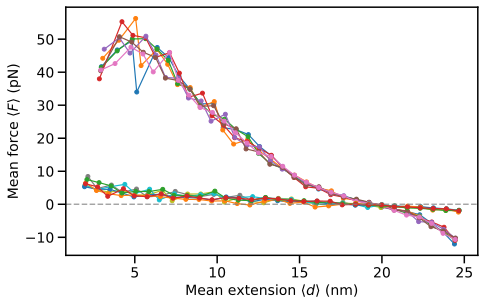

In [31]:
from collections import defaultdict
import numpy as np

# Unit conversion factors
DIST_CONVERSION = 0.8   # to nm
FORCE_CONVERSION = 48.6 # to pN

def _normalize_group_keys(group_keys):
    if group_keys is None:
        return None
    if isinstance(group_keys, str):
        return [group_keys]
    return list(group_keys)

def plot_force_extension(stats_dict, group_keys=None, figsize=(7, 4.5), show_legend=False):
    grouped = defaultdict(list)
    selected_groups = _normalize_group_keys(group_keys)

    for subfolder_name, files_dict in stats_dict.items():
        if selected_groups is not None and subfolder_name not in selected_groups:
            continue

        for (K, r0, seed), stats in files_dict.items():
            grouped[(subfolder_name, K, seed)].append((stats['dist_mean'], stats['F_mean']))

    if not grouped:
        print(f"No trajectories found for groups: {selected_groups}")
        return

    fig, ax = plt.subplots(figsize=figsize)

    for (subfolder_name, K, seed), points in grouped.items():
        points = np.array(sorted(points, key=lambda p: p[0]))
        x = DIST_CONVERSION * points[:, 0]
        y = FORCE_CONVERSION * points[:, 1]
        ax.plot(x, y, marker='o', linewidth=1.2, markersize=4,
                label=f"{subfolder_name}, K={K}, seed={seed}")

    ax.axhline(0, color='gray', linestyle='dashed', alpha=0.7)
    ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)")
    ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)")

    if show_legend:
        ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

# Combined raw trajectories in a single plot (no duplicate matching)
plot_force_extension(
    stats_dict,
    group_keys=['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats'],
    show_legend=False,
)

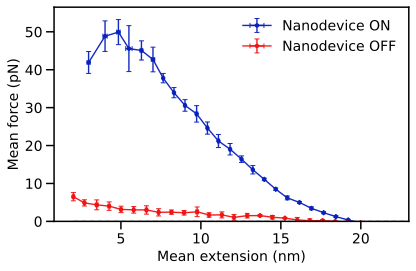


fd_4hb_mid_dats
  K=25.0: area under positive mean trajectory = 384.4305 pN*nm (10^-21 J) -> 55.330796 kcal/mol

fd_4hb_mid_staple_trials2_dats
  K=25.0: area under positive mean trajectory = 35.0062 pN*nm (10^-21 J) -> 5.038418 kcal/mol


In [50]:
#### Aggregate means/error bars across seeds (single dataset layout)
from collections import defaultdict
import numpy as np

AVOGADRO = 6.022e23  # molecules per mole

def _normalize_group_keys(group_keys):
    if group_keys is None:
        return []
    if isinstance(group_keys, str):
        return [group_keys]
    return list(group_keys)

def aggregate_by_K_r0(stats_dict, group_keys=None):
    """Aggregate mean force-extension by (K, r0) across seeds for one or more groups."""
    if not stats_dict:
        return {}

    selected_groups = _normalize_group_keys(group_keys)
    if not selected_groups:
        selected_groups = list(stats_dict.keys())

    aggregated_by_group = {}

    for group_key in selected_groups:
        files_dict = stats_dict.get(group_key, {})
        grouped = defaultdict(list)

        for (K, r0, seed), stats in files_dict.items():
            grouped[(K, r0)].append(stats)

        aggregated = defaultdict(list)
        for (K, r0), entries in grouped.items():
            dist_vals = np.array([e['dist_mean'] for e in entries])
            force_vals = np.array([e['F_mean'] for e in entries])
            ddof = 1 if len(entries) > 1 else 0

            aggregated[K].append({
                'K': K,
                'r0': r0,
                'dist_mean': dist_vals.mean(),
                'F_mean': force_vals.mean(),
                'dist_err': dist_vals.std(ddof=ddof),
                'F_err': force_vals.std(ddof=ddof),
                'n': len(entries),
            })

        for K in aggregated:
            aggregated[K] = sorted(aggregated[K], key=lambda x: x['dist_mean'])

        aggregated_by_group[group_key] = dict(aggregated)

    return aggregated_by_group

def plot_aggregated_curves_by_K(
    stats_dict,
    group_keys=None,
    group_labels=None,
    group_colors=None,
    figsize=(6, 4),
    xlim=None,
    ylim=None,
):
    aggregated_by_group = aggregate_by_K_r0(stats_dict, group_keys=group_keys)
    if not aggregated_by_group:
        print("No aggregated data available.")
        return {}, {}

    nonempty_groups = {g: d for g, d in aggregated_by_group.items() if d}
    if not nonempty_groups:
        print(f"No aggregated data available for groups: {_normalize_group_keys(group_keys)}")
        return aggregated_by_group, {}

    fig, ax = plt.subplots(figsize=figsize)

    all_x = [
        DIST_CONVERSION * point['dist_mean']
        for group_data in nonempty_groups.values()
        for points in group_data.values()
        for point in points
    ]
    if all_x:
        xmin = min(all_x) if xlim is None or xlim[0] is None else xlim[0]
        xmax = max(all_x) if xlim is None or xlim[1] is None else xlim[1]
        ax.hlines(0, xmin=xmin, xmax=xmax, colors='gray', linestyles='dashed', alpha=0.7)

    group_names = list(nonempty_groups.keys())
    n_groups = len(group_names)

    if group_labels is not None and len(group_labels) != n_groups:
        raise ValueError("group_labels must have the same length as selected groups")
    if group_colors is not None and len(group_colors) != n_groups:
        raise ValueError("group_colors must have the same length as selected groups")

    cmap = plt.get_cmap('tab10')
    area_by_group = {}

    for gi, group_name in enumerate(group_names):
        group_label = group_labels[gi] if group_labels is not None else group_name
        group_color = group_colors[gi] if group_colors is not None else cmap(gi % 10)
        group_data = nonempty_groups[group_name]
        area_by_group[group_name] = {}

        for K in sorted(group_data.keys()):
            points = group_data[K]
            x = np.array([DIST_CONVERSION * p['dist_mean'] for p in points])
            y = np.array([FORCE_CONVERSION * p['F_mean'] for p in points])
            xerr = np.array([DIST_CONVERSION * p['dist_err'] for p in points])
            yerr = np.array([FORCE_CONVERSION * p['F_err'] for p in points])

            ax.errorbar(
                x, y, xerr=xerr, yerr=yerr,
                linestyle='-', color=group_color,
                marker='o', markersize=3.5, linewidth=1.4, capsize=2.5,
                alpha=0.95,
                label=f"{group_label}"
            )

            area = np.trapezoid(np.maximum(y, 0.0), x) if len(x) > 1 else float('nan')
            area_by_group[group_name][K] = area

    ax.set_xlabel(r"Mean extension (nm)")
    ax.set_ylabel(r"Mean force (pN)")
    if xlim is not None:
        ax.set_xlim(*xlim)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.legend(frameon=False, ncol=1)
    plt.tight_layout()
    plt.show()

    for group_name, areas in area_by_group.items():
        print(f"\n{group_name}")
        for K, area in areas.items():
            kcalpermol = area * 1e-21 * AVOGADRO / 4184
            print(f"  K={K}: area under positive mean trajectory = {area:.4f} pN*nm (10^-21 J) -> {kcalpermol:.6f} kcal/mol")

    return aggregated_by_group, area_by_group

# Plot both groups together in one mean/errorbar figure
combined_aggregated_data, combined_area_by_group = plot_aggregated_curves_by_K(
    stats_dict,
    group_keys=['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats'],
    group_labels=['Nanodevice ON', 'Nanodevice OFF'],
    group_colors=["#0820bd", "#f01313"],
    xlim=(None, 23),
    ylim=(0, 56.5),
)